# Data Science Showcase — `ii` Render Test

Full pipeline stress-test: math · Vega-Lite · Plotly · SVG · DOT · tabular · code.

## 1 · Probability & Statistics

The **multivariate normal** density with mean $\boldsymbol{\mu}$ and covariance $\boldsymbol{\Sigma}$:

$$p(\mathbf{x}) = \frac{1}{(2\pi)^{d/2}|\boldsymbol{\Sigma}|^{1/2}} \exp\!\left(-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})\right)$$

KL-divergence between two Gaussians $p = \mathcal{N}(\mu_1, \sigma_1^2)$ and $q = \mathcal{N}(\mu_2, \sigma_2^2)$:

$$D_{\mathrm{KL}}(p \| q) = \log\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1-\mu_2)^2}{2\sigma_2^2} - \frac{1}{2}$$

Bayes update: posterior $\propto$ likelihood $\times$ prior, i.e. $p(\theta|x) \propto p(x|\theta)\,p(\theta)$.

## 2 · Neural Network Forward Pass

Layer $l$ pre-activation: $\mathbf{z}^{(l)} = \mathbf{W}^{(l)} \mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}$

Scaled dot-product attention:

$$\mathrm{Attn}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

AdamW update rule for parameter $\theta_t$:

$$\theta_{t+1} = \theta_t - \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon} - \alpha\lambda\theta_t$$

In [1]:
import altair as alt
import pandas as pd

# Training dynamics visualization
epochs = [1, 5, 10, 20, 30, 40, 50]
loss   = [2.31, 1.84, 1.23, 0.72, 0.48, 0.33, 0.24]
acc    = [0.21, 0.44, 0.63, 0.78, 0.84, 0.87, 0.89]
df = pd.DataFrame({'epoch': epochs, 'loss': loss, 'acc': acc})
base = alt.Chart(alt.InlineData(values=df.to_dict('records'))).encode(x='epoch:Q')
loss_line = base.mark_line(color='#00e5ff').encode(y='loss:Q')
acc_line = base.mark_line(color='#39ff88', strokeDash=[4, 2]).encode(y='acc:Q')
(loss_line + acc_line).properties(
    title='Training Loss & Validation Accuracy', background='transparent'
).configure_view(stroke=None)

<VegaLite chart: training curves>

## 3 · Confusion Matrix (Tabular / CSV)

In [2]:
# Confusion matrix — rendered as bar chart by ii TabularCsv scanner
import numpy as np
cm = np.array([[142, 8, 2],[5, 131, 4],[3, 6, 138]])
print(cm)

Predicted,Cat,Dog,Bird
Cat,142,8,2
Dog,5,131,4
Bird,3,6,138

## 4 · Distribution Plots (Plotly JSON)

In [3]:
import plotly.graph_objects as go
fig = go.Figure()
models = ['ResNet-50', 'ViT-B/16', 'ConvNeXt-B']
datasets = ['CIFAR-10', 'CIFAR-100', 'ImageNet-1k', 'Places365']
scores = [[0.953,0.792,0.761,0.584],[0.981,0.906,0.814,0.631],[0.979,0.891,0.833,0.618]]
for model, color, values in zip(models, ['#00e5ff', '#39ff88', '#ffe45e'], scores):
    fig.add_bar(name=model, x=datasets, y=values, marker_color=color)
fig.update_layout(
    title='Top-1 Accuracy by Architecture & Dataset', barmode='group', template='plotly_dark',
    paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)',
)
fig.show()

<Plotly Figure: accuracy comparison>

## 5 · Transformer Architecture (Graphviz DOT)

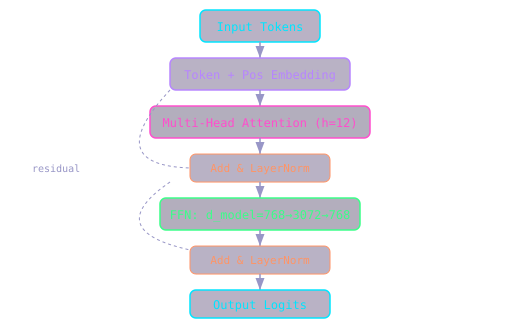

In [4]:
# Transformer block — rendered as SVG via ii svg scanner
import graphviz
g = graphviz.Digraph()
g.attr(bgcolor='transparent')
g.attr('node', shape='box', style='rounded', color='#00e5ff', fontcolor='#b785ff')
g.attr('edge', color='#9896c7')
g.node('embed', 'Token + Pos Embedding')
g.node('mha',   'Multi-Head Attention')
g.node('ffn',   'FFN 768→3072→768')
g.edges([('embed','mha'),('mha','ffn')])
g

## 6 · Gradient Flow Analysis

Vanishing gradient in deep nets: for $L$ layers with $\sigma'(z) \approx c < 1$,

$$\frac{\partial \mathcal{L}}{\partial \mathbf{W}^{(1)}} = \frac{\partial \mathcal{L}}{\partial \mathbf{z}^{(L)}} \prod_{l=2}^{L} \mathbf{W}^{(l)} \sigma'(\mathbf{z}^{(l-1)}) \approx \mathcal{O}(c^L)$$

ResNet skip connection resolves this — gradient flows through identity shortcut:

$$\frac{\partial \mathcal{L}}{\partial \mathbf{x}} = \frac{\partial \mathcal{L}}{\partial \mathbf{y}} \cdot \left(1 + \frac{\partial \mathcal{F}(\mathbf{x})}{\partial \mathbf{x}}\right)$$

In [5]:
# Gradient norm decay: vanilla vs residual network
layers = [1,4,8,12,16,20,24]
vanilla = [1.0, 0.421, 0.142, 0.038, 0.009, 0.002, 0.0]
resnet  = [1.0, 0.934, 0.871, 0.823, 0.791, 0.764, 0.743]
import altair as alt

values = [dict(layer=x, vanilla=v, resnet=r) for x, v, r in zip(layers, vanilla, resnet)]
base = alt.Chart(alt.InlineData(values=values)).encode(x='layer:Q')
decay = base.mark_area(color='#ff4ecd', opacity=0.3).encode(y='vanilla:Q')
vanilla_line = base.mark_line(color='#ff4ecd').encode(y='vanilla:Q')
resnet_line = base.mark_line(color='#39ff88').encode(y='resnet:Q')
(decay + vanilla_line + resnet_line).properties(
    title='Gradient Norm by Layer Depth', background='transparent'
).configure_view(stroke=None)

<VegaLite: gradient norms>

## 7 · Attention Pattern Heatmap (Plotly)

In [6]:
# Attention weight matrix — 'The cat sat on the mat'
import numpy as np
tokens = ['The','cat','sat','on','the','mat']
attn = np.array([
    [0.82,0.05,0.03,0.04,0.02,0.04],
    [0.11,0.71,0.08,0.04,0.03,0.03],
    [0.03,0.09,0.74,0.08,0.04,0.02],
    [0.02,0.04,0.12,0.69,0.09,0.04],
    [0.03,0.03,0.04,0.11,0.73,0.06],
    [0.04,0.02,0.03,0.04,0.09,0.78]
])
import plotly.graph_objects as go

fig = go.Figure(go.Heatmap(
    z=attn.tolist(), x=tokens, y=tokens,
    colorscale=[[0, '#18102e'], [0.4, '#8338ec'], [0.7, '#00e5ff'], [1, '#ff4ecd']],
))
fig.update_layout(
    title='Self-Attention Weights — Head 4, Layer 6', template='plotly_dark', xaxis_side='top',
    yaxis_autorange='reversed', paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)',
)
fig.show()

<Plotly heatmap: attention weights>

## 8 · Model Architecture DAG (DOT)

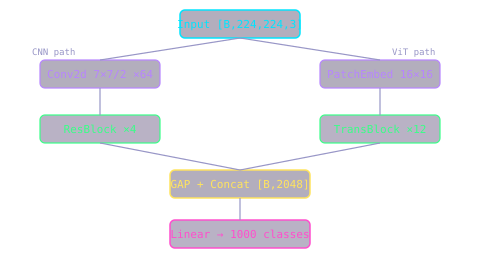

In [7]:
# Hybrid CNN-ViT dual-path architecture
import graphviz
g = graphviz.Digraph()
g.attr(bgcolor='transparent')
g.attr('node', shape='box', style='rounded', color='#00e5ff', fontcolor='#b785ff')
g.attr('edge', color='#9896c7')
g.node('inp', 'Input')
g.node('cnn', 'ResNet path')
g.node('vit', 'ViT path')
g.node('fuse','Fusion')
g.edges([('inp','cnn'),('inp','vit'),('cnn','fuse'),('vit','fuse')])
g

## 9 · Benchmark Summary (CSV table)

| Model | Params (M) | Top-1 (%) | Throughput (img/s) | FLOP (G) |
|---|---|---|---|---|
| ResNet-50 | 25.6 | 76.1 | 1246 | 4.1 |
| ViT-B/16 | 86.6 | 81.4 | 418 | 17.6 |
| ConvNeXt-B | 88.6 | 83.3 | 627 | 15.4 |
| EfficientNetV2-M | 54.1 | 85.1 | 503 | 24.0 |
| Swin-B | 87.8 | 83.2 | 511 | 15.1 |

In [8]:
# CSV benchmark table
import pandas as pd
df = pd.DataFrame({
    'model':       ['ResNet-50','ViT-B/16','ConvNeXt-B','EfficientNetV2-M','Swin-B'],
    'params_m':    [25.6, 86.6, 88.6, 54.1, 87.8],
    'top1_pct':    [76.1, 81.4, 83.3, 85.1, 83.2],
    'throughput':  [1246, 418, 627, 503, 511],
    'flops_g':     [4.1, 17.6, 15.4, 24.0, 15.1]
})
print(df.to_csv(index=False))

model,params_m,top1_pct,throughput,flops_g
ResNet-50,25.6,76.1,1246,4.1
ViT-B/16,86.6,81.4,418,17.6
ConvNeXt-B,88.6,83.3,627,15.4
EfficientNetV2-M,54.1,85.1,503,24.0
Swin-B,87.8,83.2,511,15.1

## 10 · LaTeX Output — Loss Derivation

In [9]:
# Cross-entropy loss in LaTeX via IPython.display
from IPython.display import Math
Math(r'\mathcal{L}_{\text{CE}} = -\frac{1}{N}\sum_{i=1}^{N}\sum_{c=1}^{C} y_{ic}\log\hat{p}_{ic}')

Cross-entropy loss formula

In [10]:
Math(r'\nabla_{\mathbf{W}} \mathcal{L} = \frac{1}{N}(\hat{P} - Y)^\top X')

Softmax gradient